In [1]:
import kagglehub
path = kagglehub.dataset_download("START-UMD/gtd")
print(path)

C:\Users\IT\.cache\kagglehub\datasets\START-UMD\gtd\versions\3


In [2]:
import os
import pandas as pd
import numpy as np
file=os.path.join(path,os.listdir(path)[0])
df=pd.read_csv(file,encoding='ISO-8859-1')
df.head()

C:\Users\IT\AppData\Local\Temp\ipykernel_8008\2136408751.py:5: DtypeWarning: Columns (4,6,31,33,61,62,63,76,79,90,92,94,96,114,115,121) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv(file,encoding='ISO-8859-1')


,eventid,iyear,imonth,iday,approxdate,extended,resolution,country,country_txt,region,...,addnotes,scite1,scite2,scite3,dbsource,INT_LOG,INT_IDEO,INT_MISC,INT_ANY,related
0,197000000001,1970,7,2,NaN,0,NaN,58,Dominican Republic,2,...,NaN,NaN,NaN,NaN,PGIS,0,0,0,0,NaN
1,197000000002,1970,0,0,NaN,0,NaN,130,Mexico,1,...,NaN,NaN,NaN,NaN,PGIS,0,1,1,1,NaN
2,197001000001,1970,1,0,NaN,0,NaN,160,Philippines,5,...,NaN,NaN,NaN,NaN,PGIS,-9,-9,1,1,NaN
3,197001000002,1970,1,0,NaN,0,NaN,78,Greece,8,...,NaN,NaN,NaN,NaN,PGIS,-9,-9,1,1,NaN
4,197001000003,1970,1,0,NaN,0,NaN,101,Japan,4,...,NaN,NaN,NaN,NaN,PGIS,-9,-9,1,1,NaN


In [3]:
nan=df.isna().sum()
nan

eventid            0
iyear              0
imonth             0
iday               0
approxdate    172452
               ...  
INT_LOG            0
INT_IDEO           0
INT_MISC           0
INT_ANY            0
related       156653
Length: 135, dtype: int64

In [4]:
few_nan=nan[nan.values<100].index.tolist()

In [5]:
# eventid: Unique identifier for each terrorist event
# iyear: Year in which the incident occurred
# imonth: Month of the incident (1–12; 0 if unknown)
# iday: Day of the incident (1–31; 0 if unknown)
# extended: 1 if the incident lasted more than 24 hours, 0 otherwise
# country: Numeric code representing the country where the incident occurred
# country_txt: Text name of the country
# region: Numeric code for the broader region of the incident
# region_txt: Text name of the region
# specificity: Level of geographic specificity (e.g., city, province)
# vicinity: 1 if the incident occurred in the vicinity of the city, 0 if in the city proper
# crit1: 1 if the incident meets criterion 1 (political, economic, religious, or social goal)
# crit2: 1 if the incident meets criterion 2 (intended to coerce, intimidate, or publicize)
# crit3: 1 if the incident meets criterion 3 (outside international humanitarian law)
# doubtterr: 1 if there is doubt whether the incident is an act of terrorism, 0 otherwise
# multiple: 1 if part of a coordinated attack, 0 otherwise
# success: 1 if the attack achieved its intended outcome, 0 otherwise
# suicide: 1 if the attack was a suicide attack, 0 otherwise
# attacktype1: Numeric code for the primary attack type
# attacktype1_txt: Text description of the primary attack type
# targtype1: Numeric code for the primary target type
# targtype1_txt: Text description of the primary target type
# gname: Name of the perpetrator group (e.g., Taliban, ISIS)
# individual: 1 if the attack was carried out by an individual, 0 otherwise
# weaptype1: Numeric code for the primary weapon type used
# weaptype1_txt: Text description of the primary weapon type
# property: 1 if there was property damage, 0 otherwise
# dbsource: Source(s) of the data entry (e.g., news outlets, government reports)
# INT_LOG: Indicator of whether the incident is considered international in logistical terms
# INT_IDEO: Indicator of whether the incident is international in ideological terms
# INT_MISC: Indicator of other international dimensions
# INT_ANY: 1 if any of the INT_* fields are 1, 0 otherwise

In [6]:
selected_columns = ['iyear', 'imonth', 'iday', 'extended', 'country_txt', 'region_txt', 'specificity', 'vicinity','nkill','nwound',
                    'crit1', 'crit2', 'crit3', 'doubtterr', 'multiple', 'success', 'suicide', 'attacktype1_txt',
                    'targtype1_txt', 'gname', 'individual', 'weaptype1_txt', 'property', 'dbsource',
                    'INT_LOG', 'INT_IDEO', 'INT_MISC', 'INT_ANY']

In [7]:
df_cleaned=df[selected_columns].copy()                  # without copy converting dtype into 16bit not working
df[['nkill', 'nwound']] = df[['nkill', 'nwound']].fillna(0)

In [8]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 181691 entries, 0 to 181690
Data columns (total 28 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   iyear            181691 non-null  int64  
 1   imonth           181691 non-null  int64  
 2   iday             181691 non-null  int64  
 3   extended         181691 non-null  int64  
 4   country_txt      181691 non-null  object 
 5   region_txt       181691 non-null  object 
 6   specificity      181685 non-null  float64
 7   vicinity         181691 non-null  int64  
 8   nkill            171378 non-null  float64
 9   nwound           165380 non-null  float64
 10  crit1            181691 non-null  int64  
 11  crit2            181691 non-null  int64  
 12  crit3            181691 non-null  int64  
 13  doubtterr        181690 non-null  float64
 14  multiple         181690 non-null  float64
 15  success          181691 non-null  int64  
 16  suicide          181691 non-null  int6

In [9]:
for col in df_cleaned.select_dtypes(include=['int64', 'float64']).columns:
    if df_cleaned[col].dtype == 'int64':
        df_cleaned[col] = df_cleaned[col].astype('int16')
    elif df_cleaned[col].dtype == 'float64':
        df_cleaned[col] = df_cleaned[col].astype('float16')

In [10]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 181691 entries, 0 to 181690
Data columns (total 28 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   iyear            181691 non-null  int16  
 1   imonth           181691 non-null  int16  
 2   iday             181691 non-null  int16  
 3   extended         181691 non-null  int16  
 4   country_txt      181691 non-null  object 
 5   region_txt       181691 non-null  object 
 6   specificity      181685 non-null  float16
 7   vicinity         181691 non-null  int16  
 8   nkill            171378 non-null  float16
 9   nwound           165380 non-null  float16
 10  crit1            181691 non-null  int16  
 11  crit2            181691 non-null  int16  
 12  crit3            181691 non-null  int16  
 13  doubtterr        181690 non-null  float16
 14  multiple         181690 non-null  float16
 15  success          181691 non-null  int16  
 16  suicide          181691 non-null  int1

In [11]:
df_cleaned.columns

Index(['iyear', 'imonth', 'iday', 'extended', 'country_txt', 'region_txt',
       'specificity', 'vicinity', 'nkill', 'nwound', 'crit1', 'crit2', 'crit3',
       'doubtterr', 'multiple', 'success', 'suicide', 'attacktype1_txt',
       'targtype1_txt', 'gname', 'individual', 'weaptype1_txt', 'property',
       'dbsource', 'INT_LOG', 'INT_IDEO', 'INT_MISC', 'INT_ANY'],
      dtype='object')

#### Bar Graph of Incidents by Country

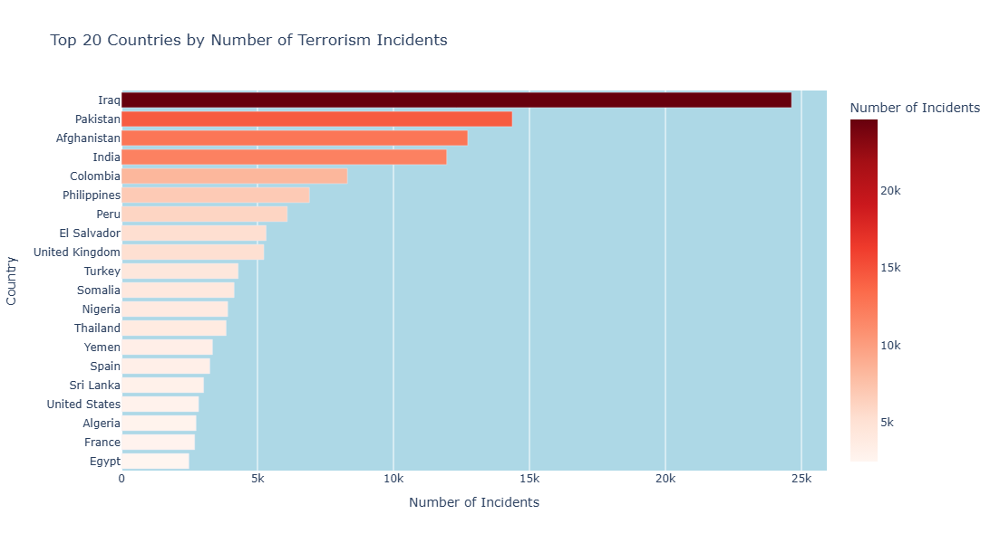

In [12]:
import plotly.express as px

# Count incidents per country
country_counts = df['country_txt'].value_counts().nlargest(20).reset_index()
country_counts.columns = ['Country', 'Incidents']

# Create interactive bar chart
fig = px.bar(
    country_counts.sort_values('Incidents'),
    x='Incidents',
    y='Country',
    orientation='h',
    title='Top 20 Countries by Number of Terrorism Incidents',
    labels={'Incidents': 'Number of Incidents', 'Country': 'Country'},
    color='Incidents',
    color_continuous_scale='Reds'
)

fig.update_layout(width=1000,height=600,yaxis=dict(dtick=1),plot_bgcolor='lightblue')
fig.show()
fig.write_image('D:/Datavis/terrorism/incidents_bargraph_bycountry.png')


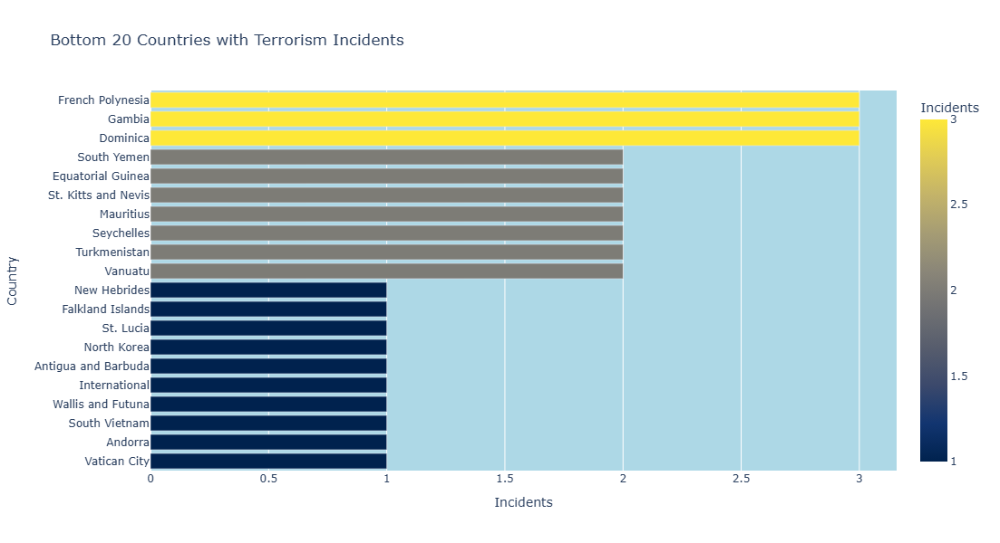

In [13]:
bottom15 = df['country_txt'].value_counts().loc[lambda x: x >= 0].nsmallest(20).reset_index()
bottom15.columns = ['Country', 'Incidents']
fig_bottom = px.bar(
    bottom15.sort_values('Incidents'),
    x='Incidents',
    y='Country',
    orientation='h',
    title='Bottom 20 Countries with Terrorism Incidents',
    color='Incidents',
    color_continuous_scale='Cividis'
)
fig_bottom.update_layout(width=1000,height=600,yaxis=dict(dtick=1),plot_bgcolor='lightblue')
fig_bottom.write_image('D:/Datavis/terrorism/low_country_terrorism.png')
fig_bottom.show()


#### Scatter Plot of Casualties vs Attack Type

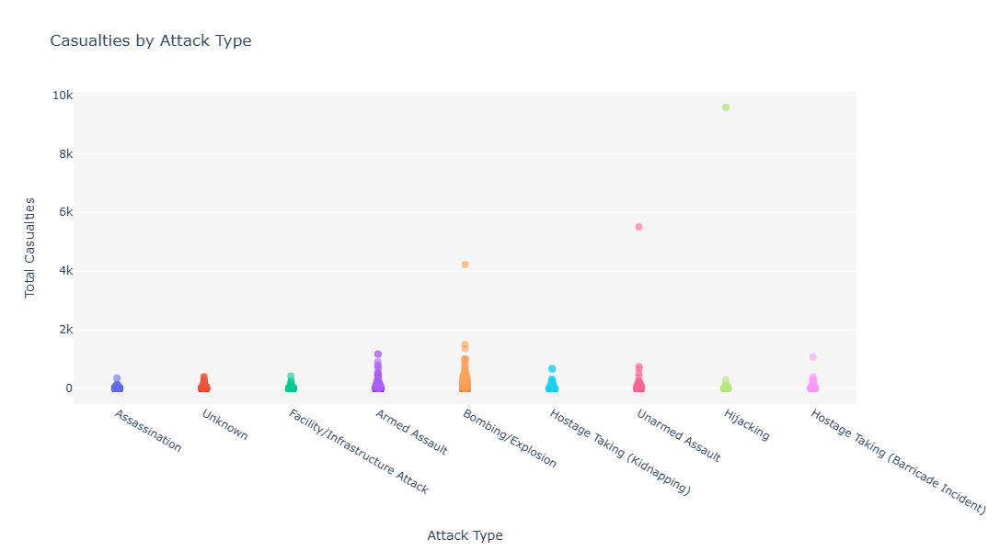

In [14]:
df_cleaned['casualties'] = df_cleaned['nkill'] + df_cleaned['nwound']
df_filtered = df_cleaned[df_cleaned['casualties'] > 0]

# Create scatter plot
fig = px.strip(
    df_filtered,
    x='attacktype1_txt',
    y='casualties',
    color='attacktype1_txt',
    title='Casualties by Attack Type',
    labels={'attacktype1_txt': 'Attack Type', 'casualties': 'Total Casualties'},
    hover_data=['country_txt', 'region_txt', 'gname'])

fig.update_traces(jitter=0.1, marker=dict(size=8, opacity=0.6))
fig.update_layout(
    width=1000,
    height=600,
    showlegend=False,
    plot_bgcolor='whitesmoke',
    paper_bgcolor='white')
fig.show()
fig.write_image('D:/Datavis/terrorism/scatter_casualvsattack.png')


#### Subplots: Incidents by Year and Attack Type

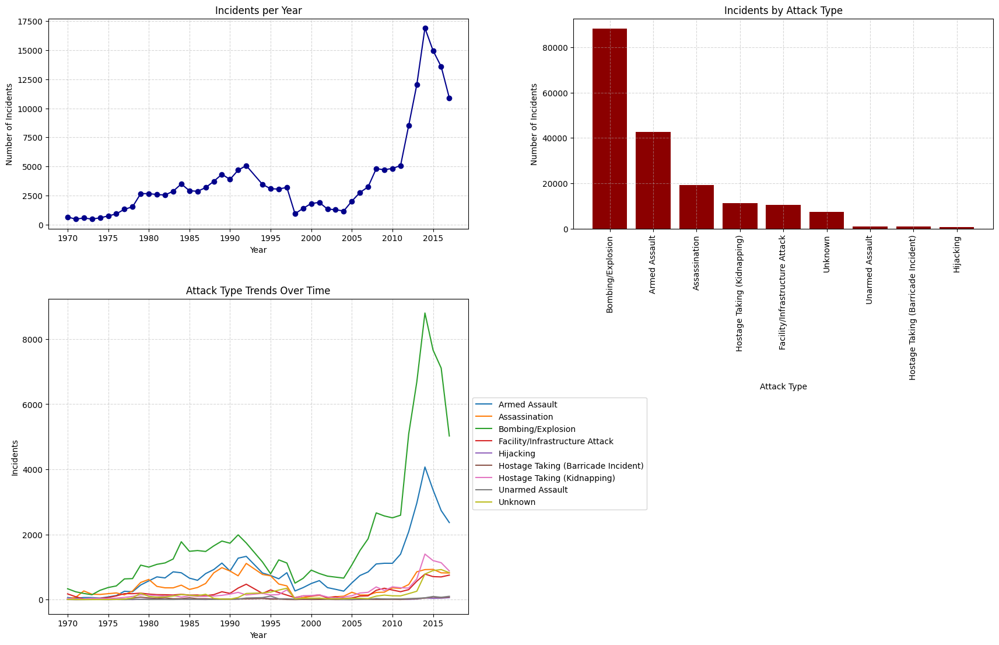

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# Prepare data
yearly_counts = df_cleaned['iyear'].value_counts().sort_index()
attack_counts = df_cleaned['attacktype1_txt'].value_counts()
attack_trend = df_cleaned.groupby(['iyear', 'attacktype1_txt']).size().unstack(fill_value=0)

# Create figure
fig = plt.figure(figsize=(18, 12))

# Subplot 1: Incidents per year (top-left)
ax1 = fig.add_axes([0.05, 0.65, 0.4, 0.3])  # [left, bottom, width, height]
ax1.plot(yearly_counts.index, yearly_counts.values, marker='o', color='darkblue')
ax1.set_title('Incidents per Year')
ax1.set_xlabel('Year')
ax1.set_ylabel('Number of Incidents')
ax1.set_xticks(range(yearly_counts.index.min(), yearly_counts.index.max()+1, 5))
ax1.grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Incidents by attack type (top-right)
ax2 = fig.add_axes([0.55, 0.65, 0.4, 0.3])
ax2.bar(attack_counts.index, attack_counts.values, color='darkred')
ax2.set_title('Incidents by Attack Type')
ax2.set_xlabel('Attack Type')
ax2.set_ylabel('Number of Incidents')
ax2.tick_params(axis='x', rotation=90)
ax2.grid(True, linestyle='--', alpha=0.5)

# Subplot 3: Attack type trends over time (bottom full-width)
ax3 = fig.add_axes([0.05, 0.1, 0.4, 0.45])
for attack_type in attack_trend.columns:
    ax3.plot(attack_trend.index, attack_trend[attack_type], label=attack_type)
ax3.set_title('Attack Type Trends Over Time')
ax3.set_xlabel('Year')
ax3.set_ylabel('Incidents')
ax3.set_xticks(range(attack_trend.index.min(), attack_trend.index.max()+1, 5))
ax3.legend(loc='upper left', bbox_to_anchor=(1, 0.7))
ax3.grid(True, linestyle='--', alpha=0.5)
plt.savefig('D:/Datavis/terrorism/subplots_year_attype.png')
plt.show()

#### Heatmap of Attack Type vs Target Type

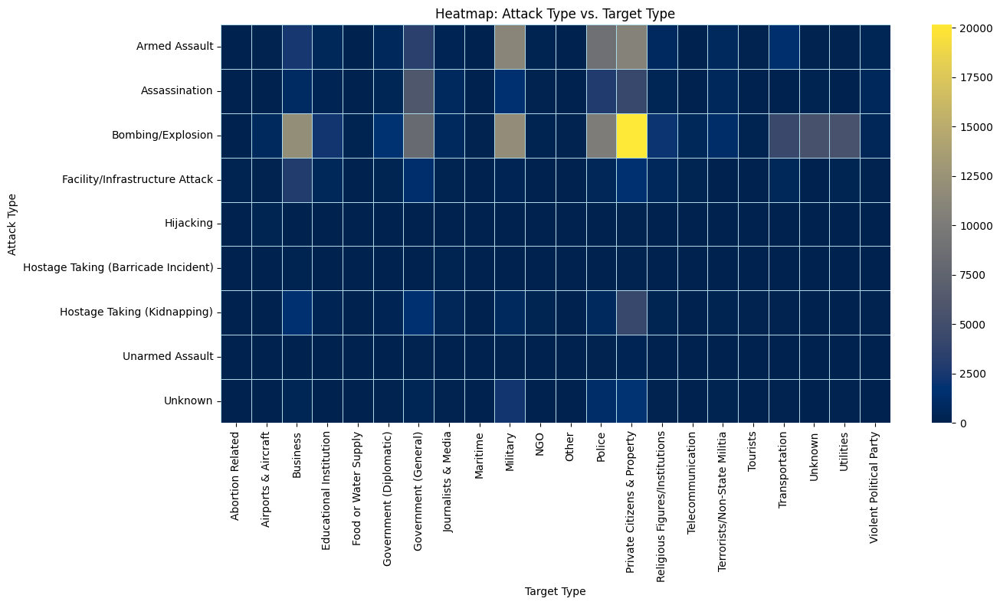

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create pivot table: rows = attack types, columns = target types
heatmap_data = df_cleaned.pivot_table(
    index='attacktype1_txt',
    columns='targtype1_txt',
    values='iyear',
    aggfunc='count',
    fill_value=0
)

# Plot heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(heatmap_data, cmap='cividis', linewidths=0.5,linecolor='lightblue')

plt.title('Heatmap: Attack Type vs. Target Type')
plt.xlabel('Target Type')
plt.ylabel('Attack Type')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('D:/Datavis/terrorism/heatmap_attckvstarget.png')
plt.show()

In [17]:
import geopandas as gpd
world = gpd.read_file('D:/Datavis/ne_110m_admin_0_countries.shp')

In [18]:
world.head()

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
0,Admin-0 country,1,6,Fiji,FJI,0,2,Sovereign country,1,Fiji,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((180 -16.06713, 180 -16.55522, ..."
1,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,None,None,None,None,None,None,None,None,None,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3..."
2,Admin-0 country,1,7,Western Sahara,SAH,0,2,Indeterminate,1,Western Sahara,...,Unrecognized,Unrecognized,Unrecognized,None,None,Unrecognized,None,None,None,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948..."
3,Admin-0 country,1,2,Canada,CAN,0,2,Sovereign country,1,Canada,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025..."
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."


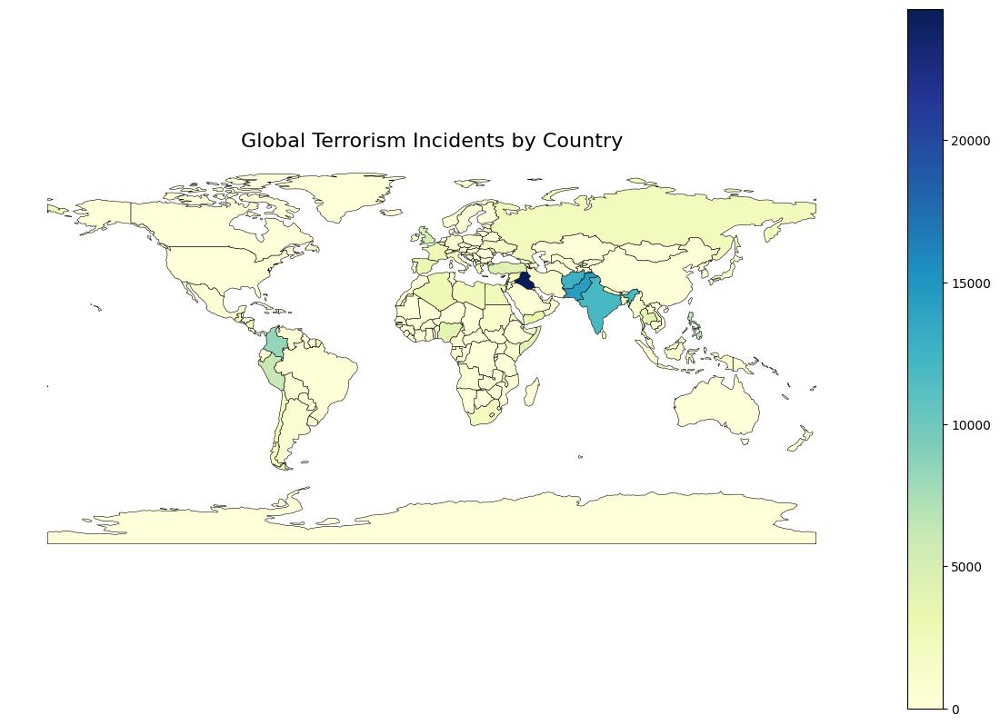

In [19]:
country_counts = df_cleaned['country_txt'].value_counts().reset_index()
country_counts.columns = ['country_txt', 'incident_count']
world = world.merge(country_counts, how='left', left_on='NAME', right_on='country_txt')
world['incident_count'] = world['incident_count'].fillna(0)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(15, 10))
world.plot(column='incident_count', ax=ax, legend=True,
           cmap='YlGnBu', edgecolor='black', linewidth=0.4)
ax.set_title('Global Terrorism Incidents by Country', fontsize=16)
plt.axis('off')

plt.show()

In [20]:
country_counts['country_txt'].isin(world['NAME']).value_counts()

country_txt
True     151
False     54
Name: count, dtype: int64

#### Chloropleth Map of Incidents by Country

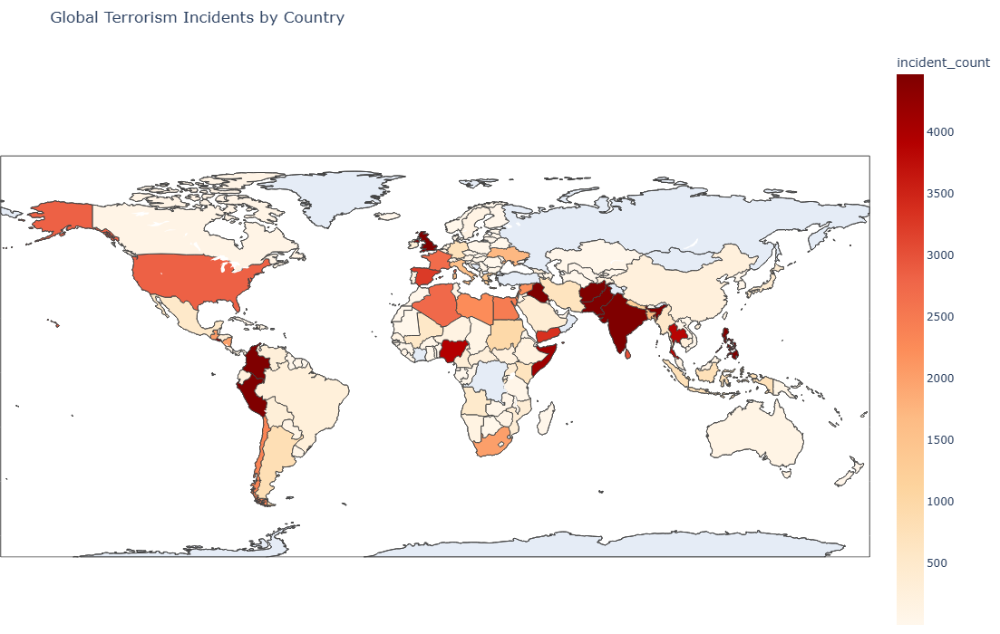

In [21]:
import pandas as pd
import plotly.express as px
import pycountry

# Step 1: Aggregate incident counts by country
country_counts = df_cleaned['country_txt'].value_counts().reset_index()
country_counts.columns = ['country_txt', 'incident_count']

# Step 2: Map country names to ISO Alpha-3 codes
def get_iso3(name):
    try:
        return pycountry.countries.lookup(name).alpha_3
    except:
        return None

country_counts['iso_alpha'] = country_counts['country_txt'].apply(get_iso3)
country_counts = country_counts.dropna(subset=['iso_alpha'])

# Step 3: Filter out zero-incident countries (optional)
filtered_df = country_counts[country_counts['incident_count'] >= 0]

# Step 4: Create interactive choropleth map
fig = px.choropleth(
    filtered_df,
    locations='iso_alpha',
    color='incident_count',
    hover_name='country_txt',
    color_continuous_scale='OrRd',
    range_color=(1, filtered_df['incident_count'].quantile(0.95)),  # compress scale
    title='Global Terrorism Incidents by Country'
)

# Step 5: Customize layout
fig.update_geos(showcountries=True, showcoastlines=True, showland=True, fitbounds="locations")
fig.update_layout(
    width=1100,
    height=700,
    margin={"r":0,"t":50,"l":0,"b":0}
)

fig.show()

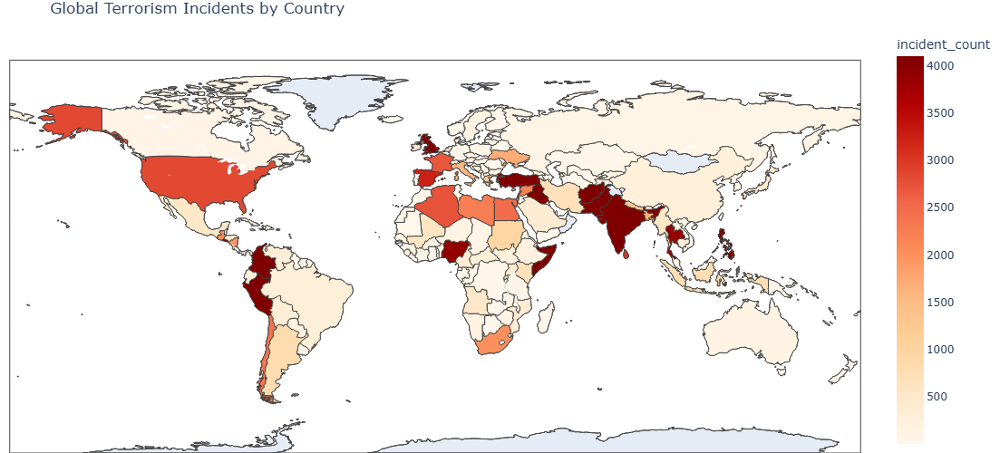

In [22]:
country_counts = df_cleaned['country_txt'].value_counts().reset_index()
manual_iso_map = {'Russia': 'RUS','Turkey': 'TUR','West Bank and Gaza Strip': 'PSE','Democratic Republic of the Congo': 'COD',
    'West Germany (FRG)': 'DEU','Yugoslavia': 'SRB','Kosovo': 'XKX','Bosnia-Herzegovina': 'BIH','Macedonia': 'MKD',
    'Rhodesia': 'ZWE','Soviet Union': 'RUS','Ivory Coast': 'CIV','Zaire': 'COD','East Germany (GDR)': 'DEU',
    'Macau': 'MAC','Swaziland': 'SWZ','Serbia-Montenegro': 'SRB','East Timor': 'TLS','Czechoslovakia': 'CZE',
    'North Yemen': 'YEM','Brunei': 'BRN',"People's Republic of the Congo": 'COG','St. Kitts and Nevis': 'KNA',
    'South Yemen': 'YEM','Vatican City': 'VAT','Falkland Islands': 'FLK','St. Lucia': 'LCA','New Hebrides': 'VUT',
    'International': None,'South Vietnam': 'VNM'}
country_counts.columns = ['country_txt', 'incident_count']

def get_iso3(name):
    try:
        return pycountry.countries.lookup(name).alpha_3
    except:
        return None

country_counts['iso_alpha'] = country_counts['country_txt'].apply(get_iso3)
country_counts['iso_alpha'] = country_counts.apply(
    lambda row: manual_iso_map.get(row['country_txt'], row['iso_alpha']),axis=1)
country_counts = country_counts.dropna(subset=['iso_alpha'])
# country_counts['iso_alpha']=country_counts['iso_alpha'].fillna(0)
# country_counts[country_counts.loc[:,'iso_alpha']==0]['country_txt']
fig = px.choropleth(
    country_counts,
    locations='iso_alpha',
    color='incident_count',
    hover_name='country_txt',
    color_continuous_scale='OrRd',
    range_color=(1, country_counts['incident_count'].quantile(0.95)),
    title='Global Terrorism Incidents by Country'
)

fig.update_geos(showcountries=True, showcoastlines=True, showland=True, fitbounds="locations")
fig.update_layout(
    width=1100,
    height=500,
    margin={"r":0,"t":30,"l":0,"b":0}
)
fig.show()
fig.write_image('D:/Datavis/terrorism/incidents_country.png')

#### 3D Plot

In [23]:
import plotly.graph_objects as go

df_cleaned[['iyear','region_txt','casualties']]=df_cleaned.loc[:,['iyear','region_txt','casualties']].fillna(0)
fig = go.Figure(data=[
    go.Scatter3d(
        x=df_cleaned['iyear'],
        y=df_cleaned['region_txt'],
        z=df_cleaned['casualties'],
        mode='markers',
        marker=dict(
            size=5,
            color=df_cleaned['casualties'],
            colorscale='Inferno',
            opacity=0.7
        )
    )
])

fig.update_layout(
    scene=dict(
        xaxis_title='Year',
        yaxis_title='Region',
        zaxis_title='Casualties'),title='3D Visualization of Terrorism Casualties by Year and Region',width=1500,height=800)
fig.show()


In [24]:
import plotly.graph_objects as go
from sklearn.preprocessing import LabelEncoder

# Encode region_txt to numeric values
le = LabelEncoder()
df_cleaned['region_code'] = le.fit_transform(df_cleaned['region_txt'])

# Create 3D scatter plot
fig = go.Figure(data=[
    go.Scatter3d(
        x=df_cleaned['region_txt'],
        y=df_cleaned['iyear'],
        z=df_cleaned['casualties'],
        mode='markers',
        marker=dict(
            size=5,
            color=df_cleaned['region_code'],  # Correct: same length as data
            colorscale='Inferno',
            opacity=0.7,
            colorbar=dict(title='Region Code')
        )
    )
])

fig.update_layout(
    scene=dict(
        xaxis_title='Year',
        yaxis_title='Region',
        zaxis_title='Casualties'
    ),
    title='3D Visualization of Terrorism Casualties by Year and Region',
    width=1500,
    height=800
)

fig.show()
fig.write_image('D:/Datavis/terrorism/3dplot.png')

#### Contour plots

C:\Users\IT\AppData\Local\Temp\ipykernel_8008\1494801479.py:3: DeprecationWarning:

The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.



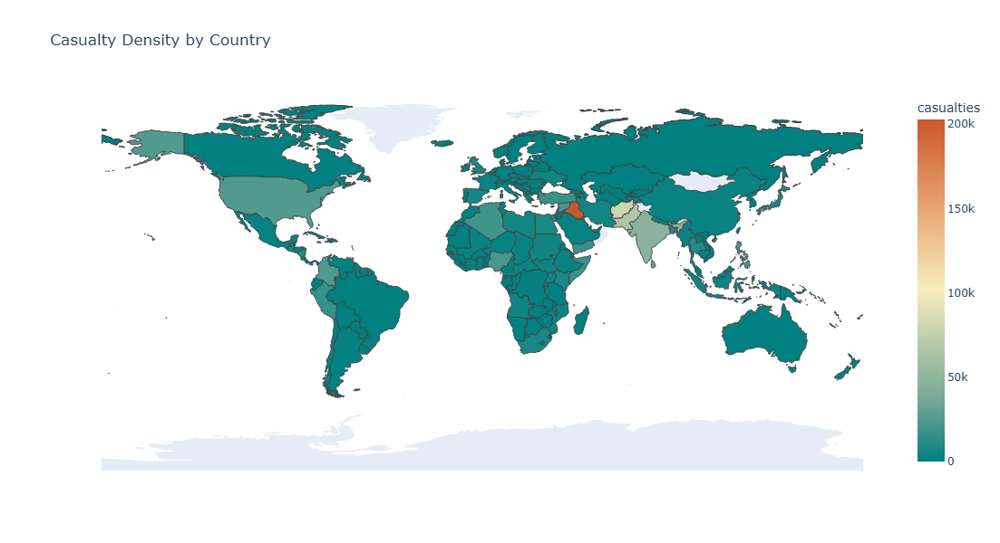

In [25]:
casualty_by_country = df_cleaned.groupby('country_txt')['casualties'].sum().reset_index()

fig = px.choropleth(casualty_by_country, locations='country_txt',
                    locationmode='country names', color='casualties',
                    title='Casualty Density by Country',color_continuous_scale='geyser')
fig.update_layout(geo=dict(showframe=False, showcoastlines=False,showcountries=False,
                          showlakes=False,showrivers=False),width=1100,height=600)
fig.show()
fig.write_image('D:/Datavis/terrorism/chloropeth_country_casualties.png')

C:\Users\IT\AppData\Local\Temp\ipykernel_8008\2332331894.py:4: DeprecationWarning:

*density_mapbox* is deprecated! Use *density_map* instead. Learn more at: https://plotly.com/python/mapbox-to-maplibre/



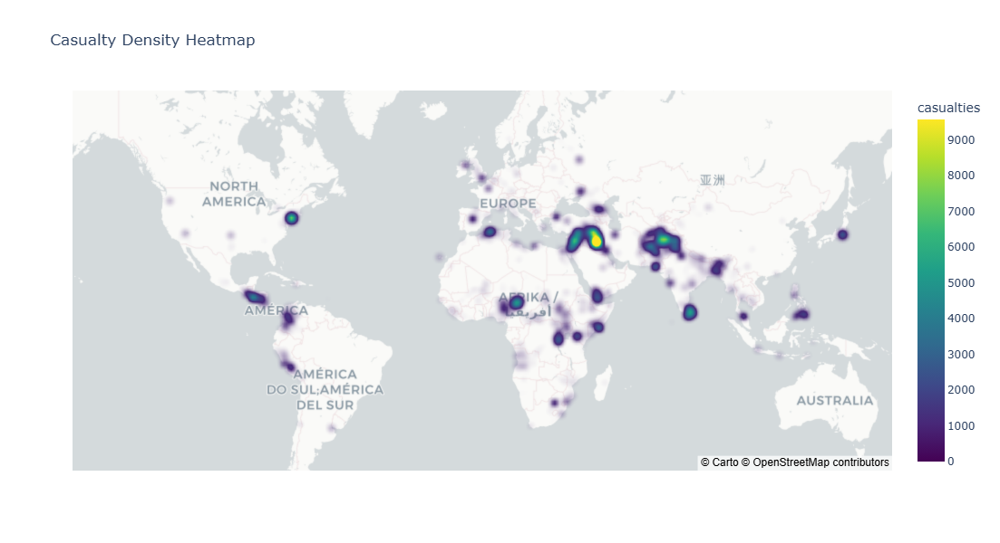

In [ ]:
import plotly.express as px
df['casualties'] = df['nkill'].fillna(0) + df['nwound'].fillna(0)
df_clean = df[(df['latitude'].between(-90, 90)) & (df['longitude'].between(-180, 180))]
fig = px.density_mapbox(df_clean, lat='latitude', lon='longitude', z='casualties',
                        radius=10, center=dict(lat=20, lon=0), zoom=1,
                        mapbox_style='carto-positron',color_continuous_scale='viridis',
                        title='Casualty Density Heatmap')
fig.update_layout(width=1000,height=600)
fig.show()
fig.write_image('D:/Datavis/terrorism/contour.png')